<a href="https://colab.research.google.com/github/Daria720/ML/blob/main/ML_%D0%94%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80_%D0%93%D0%BE%D0%BC%D0%BE%D0%BD%D1%8E%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Задача прогнозування відтоку клієнтів
**Виконала:** Гомонюк Дар'я ФІТ 3-10

**Набір даних:** Bank Customer Churn Prediction (`Churn_Modelling.csv`, джерело: Kaggle)  
**Мета роботи:** провести розвідувальний аналіз та підготовку даних, побудувати й порівняти моделі машинного навчання для класифікації клієнтів за ризиком відтоку, підібрати оптимальні гіперпараметри для найкращої моделі та виконати прогноз для нового клієнта.

In [6]:
# Імпорт бібліотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix

In [7]:
# 1.Завантаження даних
url = "https://raw.githubusercontent.com/sharmaroshan/Churn-Modelling-Dataset/master/Churn_Modelling.csv"
df = pd.read_csv(url)

print("Розмір датасету:", df.shape)
display(df.head())

Розмір датасету: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Пропущені значення:
 RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Баланс класів (0 - залишився, 1 - пішов):
 Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


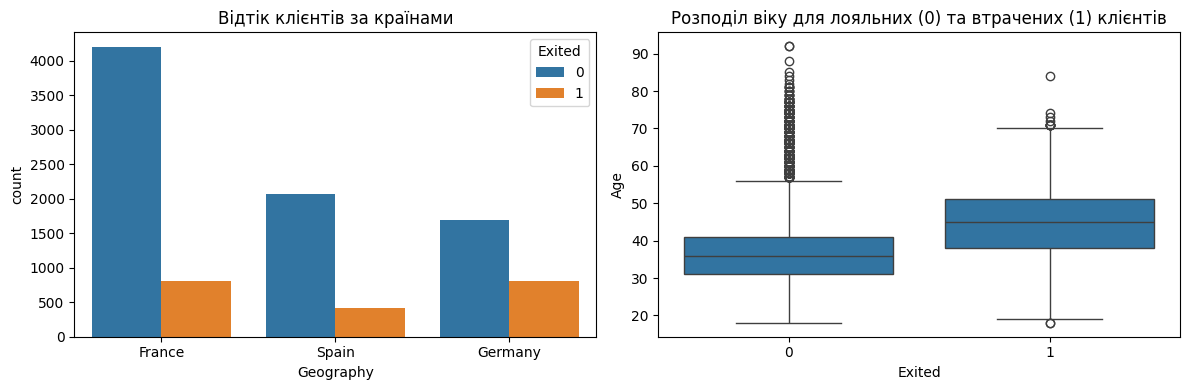

In [8]:
# 2.Первинний аналіз даних(EDA)
print("\nПропущені значення:\n", df.isnull().sum())
print("\nБаланс класів (0 - залишився, 1 - пішов):\n", df['Exited'].value_counts(normalize=True).round(3))

# Візуалізація відтоку за країнами та віком
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Geography', hue='Exited', ax=axes[0])
axes[0].set_title('Відтік клієнтів за країнами')

sns.boxplot(data=df, x='Exited', y='Age', ax=axes[1])
axes[1].set_title('Розподіл віку для лояльних (0) та втрачених (1) клієнтів')
plt.tight_layout()
plt.show()


In [9]:
print("Кількість дублікатів:", df.duplicated().sum())
display(df.describe().round(2))

Кількість дублікатів: 0


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,5000.50,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,2886.90,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,1.00,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,2500.75,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,5000.50,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,7500.25,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,10000.00,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


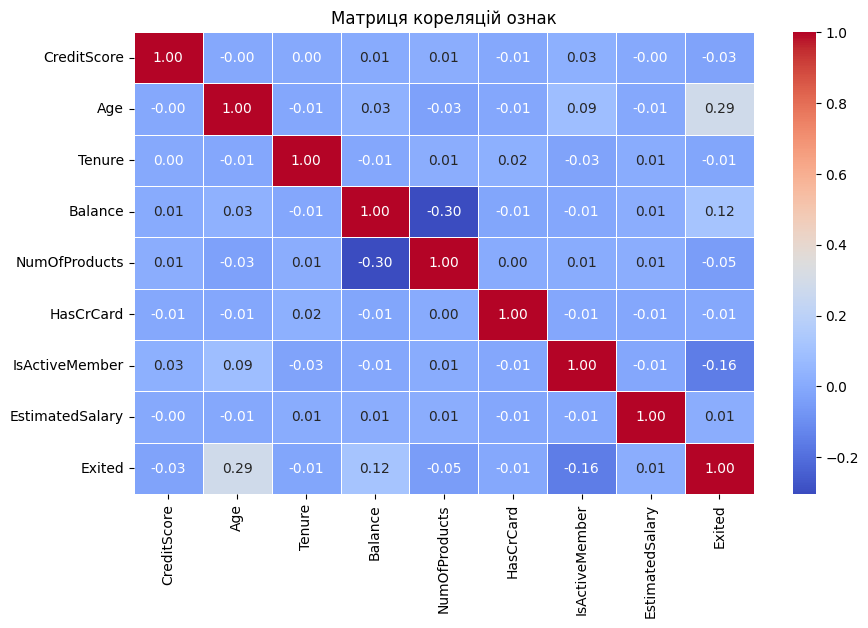

In [10]:
# Матриця кореляцій для числових стовпців
plt.figure(figsize=(10, 6))
numeric_df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Geography', 'Gender'])
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Матриця кореляцій ознак')
plt.show()

In [11]:
# 3.Підготовка даних
# Видаляємо стовпці-ідентифікатори, які не несуть корисної інформації для прогнозу
df_clean = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

X = df_clean.drop('Exited', axis=1)
y = df_clean['Exited']

num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
cat_cols = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember']

# Пайплайн для масштабування числових та кодування категоріальних ознак
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first'), cat_cols)
])

# Розділяємо на навчальну та тестову вибірки (80% / 20%) зі збереженням пропорції класів
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [12]:
# 4.Навчання та порівняння моделей
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

results = []
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', clf)])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    results.append({
        'Модель': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'F1-score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    })

results_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
print("\nПорівняння базових моделей:")
display(results_df)


Порівняння базових моделей:


,Модель,Accuracy,F1-score,ROC-AUC
2,Gradient Boosting,0.8700,0.6049,0.8708
1,Random Forest,0.8600,0.5611,0.8535
0,Logistic Regression,0.7135,0.4987,0.7771


In [13]:
# 5.Підбір параметрів для найкращої моделі (Gradient Boosting)
gb_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', GradientBoostingClassifier(random_state=42))
])

param_grid = {
    'model__n_estimators': [100, 150],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [3, 4]
}

grid_search = GridSearchCV(gb_pipe, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)
y_prob_best = best_model.predict_proba(X_test)[:, 1]

print("\nНайкращі параметри:", grid_search.best_params_)
print(f"Покращений ROC-AUC: {roc_auc_score(y_test, y_prob_best):.4f}")
print("\nЗвіт класифікації для найкращої моделі:\n", classification_report(y_test, y_pred_best))


Найкращі параметри: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 100}
Покращений ROC-AUC: 0.8697

Звіт класифікації для найкращої моделі:
               precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.81      0.46      0.59       407

    accuracy                           0.87      2000
   macro avg       0.85      0.72      0.76      2000
weighted avg       0.86      0.87      0.85      2000



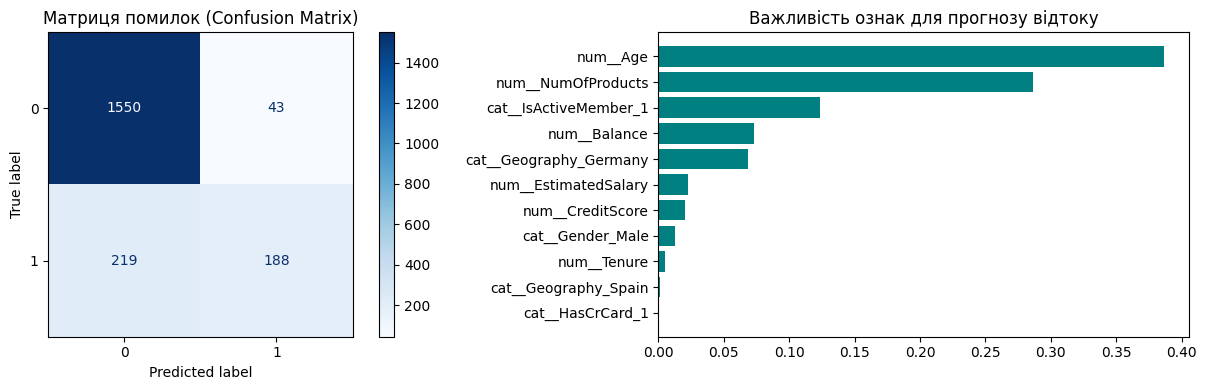

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

#Матриця помилок
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, cmap='Blues', ax=axes[0])
axes[0].set_title('Матриця помилок (Confusion Matrix)')

#Важливість ознак
feature_names = best_model.named_steps['prep'].get_feature_names_out()
importances = best_model.named_steps['model'].feature_importances_
feat_df = pd.DataFrame({'Ознака': feature_names, 'Важливість': importances}).sort_values('Важливість', ascending=True)

axes[1].barh(feat_df['Ознака'], feat_df['Важливість'], color='teal')
axes[1].set_title('Важливість ознак для прогнозу відтоку')
plt.tight_layout()
plt.show()

In [15]:
# 6.Прогноз для нового клієнта
new_client = pd.DataFrame([{
    'CreditScore': 610,
    'Geography': 'Germany',
    'Gender': 'Female',
    'Age': 46,
    'Tenure': 3,
    'Balance': 125000.0,
    'NumOfProducts': 1,
    'HasCrCard': 1,
    'IsActiveMember': 0,
    'EstimatedSalary': 85000.0
}])

prediction = best_model.predict(new_client)[0]
probability = best_model.predict_proba(new_client)[0][1]

status = "Піде (високий ризик відтоку)" if prediction == 1 else "Залишиться (лояльний клієнт)"
print(f"\nРезультат прогнозу для клієнта: {status}")
print(f"Ймовірність відтоку: {probability * 100:.2f}%")


Результат прогнозу для клієнта: Піде (високий ризик відтоку)
Ймовірність відтоку: 72.94%


**Висновок:**

Під час виконання лабораторної роботи я проаналізувала датасет клієнтів банку та підготувала його до навчання, прибравши зайві стовпці й закодувавши категоріальні ознаки. Аналіз показав, що вибірка незбалансована, оскільки більшість клієнтів залишаються лояльними, а найбільше на відтік впливають вік, активність та кількість підключених продуктів. Серед усіх перевірених алгоритмів найкращий результат показав градієнтний бустинг, особливо після підбору оптимальних параметрів через GridSearchCV. На тестовій вибірці ця модель досягла показника ROC-AUC близько 0.87 і добре впоралася з розділенням класів. Наприкінці я перевірила роботу моделі на даних нового клієнта та переконалася, що вона коректно визначає як сам прогноз, так і ймовірність його відтоку.